# Trabajo Práctico — Matemática IV (2026) — Conjunto A
**Consumo eléctrico de una planta siderúrgica** — Facultad de Informática

Notebook autocontenido y reproducible (Google Colab o Jupyter local). Resuelve en orden:

| Bloque | Contenido |
|:---|:---|
| Carga | Validación de `Steel_industry_data.csv` ($n=35\,040$ filas, 11 columnas) |
| **A.1** | Modelo cuadrático Usage_kWh ~ NSM: derivadas, punto crítico, comparación con lineal |
| **A.2** | Derivadas parciales y ecuaciones normales de la regresión simple (Lagging kVarh) |
| **A.3** | Descenso del gradiente de la regresión múltiple (B.5) con 3 tasas de aprendizaje |
| **B.1** | Descomposición $STC=SCR+SCE$, $\hat{\sigma}^2$, $R^2$ y sus limitaciones |
| **B.2** | Cuatro regresiones simples con IC, ICM e IP (95%) y selección de la mejor predictora |
| **B.3** | Test de hipótesis $H_0:\beta_1=0$ sobre el mejor modelo |
| **B.4** | ICM e IP con sustitución numérica en $x^{*}=20$ kVarh |
| **B.5** | Regresión múltiple matricial $\hat{\beta}=(X^TX)^{-1}X^TY$ y $R^2$ ajustado (ambas fórmulas) |

> **Cómo ejecutar en Colab:** solo se requiere la última celda de instalación (opcional) y "Ejecutar todo".
> Si el CSV no está en el entorno, se descarga automáticamente del repositorio fuente.
> La variable prohibida `CO2(tCO2)` **no** se usa como predictora en ningún modelo.

In [1]:
!pip install -q pandas numpy scipy statsmodels matplotlib seaborn

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats

np.random.seed(42)
plt.rcParams['figure.dpi'] = 110
os.makedirs('figures', exist_ok=True)
print('Librerías cargadas — semilla fijada: np.random.seed(42)')

Librerías cargadas — semilla fijada: np.random.seed(42)


In [3]:
def cargar_datos():
    rutas = ['Steel_industry_data.csv', '../Steel_industry_data.csv', '/content/Steel_industry_data.csv']
    for p in rutas:
        if os.path.exists(p):
            return pd.read_csv(p)
    url = 'https://raw.githubusercontent.com/ericruizs/Energy-Predictions-for-Steel-Factory/main/Steel_industry_data.csv'
    return pd.read_csv(url)

df = cargar_datos()

# Validaciones obligatorias
assert df.shape == (35040, 11)
assert df.isnull().sum().sum() == 0
assets = ['Usage_kWh', 'NSM', 'Lagging_Current_Reactive.Power_kVarh']
for a in assets:
    assert a in df.columns

print(f'Dataset válido: {df.shape[0]} filas x {df.shape[1]} columnas, sin nulos')
df[assets].describe().round(3)

Dataset válido: 35040 filas x 11 columnas, sin nulos


,Usage_kWh,NSM,Lagging_Current_Reactive.Power_kVarh
count,35040.000,35040.000,35040.000
mean,27.387,42750.000,13.035
std,33.444,24940.534,16.306
min,0.000,0.000,0.000
25%,3.200,21375.000,2.300
50%,4.570,42750.000,5.000
75%,51.238,64125.000,22.640
max,157.180,85500.000,96.910


---
## A.1 — Derivación: modelo cuadrático de Usage_kWh en función de NSM

Se ajusta $\hat{y}(x)=\beta_0+\beta_1x+\beta_2x^2$ (MCO matricial), se deriva $d\hat{y}/dx=\hat{\beta}_1+2\hat{\beta}_2x$,
se evalúa en 04:00 y 18:00, se compara con la derivada **constante** del modelo lineal y se halla el punto crítico
$x_c=-\hat{\beta}_1/(2\hat{\beta}_2)$, clasificado con la segunda derivada $2\hat{\beta}_2$.

In [7]:
x_nsm = df['NSM'].values
y_usage = df['Usage_kWh'].values
n = len(y_usage)

# --- Modelo cuadrático ---
Xq = np.column_stack([np.ones(n), x_nsm, x_nsm**2])
bq = np.linalg.inv(Xq.T @ Xq) @ Xq.T @ y_usage
b0q, b1q, b2q = bq

# Validación con statsmodels (tolerancia relajada a 1e-9 para evitar problemas de precisión numérica)
bq_sm = sm.OLS(y_usage, sm.add_constant(np.column_stack([x_nsm, x_nsm**2]))).fit().params
assert np.abs(bq - bq_sm).max() < 1e-9

# --- Modelo lineal ---
Xl = np.column_stack([np.ones(n), x_nsm])
bl = np.linalg.inv(Xl.T @ Xl) @ Xl.T @ y_usage
b0l, b1l = bl
assert np.abs(bl - sm.OLS(y_usage, sm.add_constant(x_nsm)).fit().params).max() < 1e-9

print(f'CUADRÁTICO:  ŷ = {b0q:.4f} + {b1q:.4e}·x + {b2q:.4e}·x²')
print(f'LINEAL:      ŷ = {b0l:.4f} + {b1l:.4e}·x')
print()

# --- Derivadas evaluadas en dos puntos representativos ---
x1, x2 = 14400, 64800                 # 04:00 y 18:00
dy1 = b1q + 2*b2q*x1                  # kWh/s
dy2 = b1q + 2*b2q*x2
print(f'dŷ/dx (cuadrático) = {b1q:.4e} + 2·({b2q:.2e})·x')
print(f'  x₁={x1} s (04:00): {dy1:.4e} kWh/s = {dy1*3600:+.2f} kWh/hora')
print(f'  x₂={x2} s (18:00): {dy2:.4e} kWh/s = {dy2*3600:+.2f} kWh/hora')
print(f'  LINEAL (constante):          {b1l:.4e} kWh/s = {b1l*3600:+.2f} kWh/hora')
print()

# --- Punto crítico ---
xc = -b1q / (2*b2q)
d2y = 2*b2q
tipo = 'máximo' if d2y < 0 else 'mínimo'
en_rango = 0 <= xc <= 85500
hh, mm, ss = int(xc // 3600), int(xc % 3600 // 60), int(xc % 60)
yc = b0q + b1q*xc + b2q*xc**2
print(f'PUNTO CRÍTICO:  x_c = {xc:.2f} s = {hh:02d}:{mm:02d}:{ss:02d}')
signo = '< 0' if d2y < 0 else '> 0'
print(f'  segunda derivada 2β₂ = {d2y:.4e} {signo}  →  {tipo} local/absoluto en la parábola')
print(f'  dentro de [0, 85500]?  {en_rango}')
print(f'  ŷ(x_c) = {yc:.2f} kWh por intervalo de 15 min  (~{yc*4:.0f} kW promedio)')

CUADRÁTICO:  ŷ = -16.4210 + 2.4677e-03·x + -2.5182e-08·x²
LINEAL:      ŷ = 13.9376 + 3.1460e-04·x

dŷ/dx (cuadrático) = 2.4677e-03 + 2·(-2.52e-08)·x
  x₁=14400 s (04:00): 1.7424e-03 kWh/s = +6.27 kWh/hora
  x₂=64800 s (18:00): -7.9594e-04 kWh/s = -2.87 kWh/hora
  LINEAL (constante):          3.1460e-04 kWh/s = +1.13 kWh/hora

PUNTO CRÍTICO:  x_c = 48996.53 s = 13:36:36
  segunda derivada 2β₂ = -5.0365e-08 < 0  →  máximo local/absoluto en la parábola
  dentro de [0, 85500]?  True
  ŷ(x_c) = 44.03 kWh por intervalo de 15 min  (~176 kW promedio)


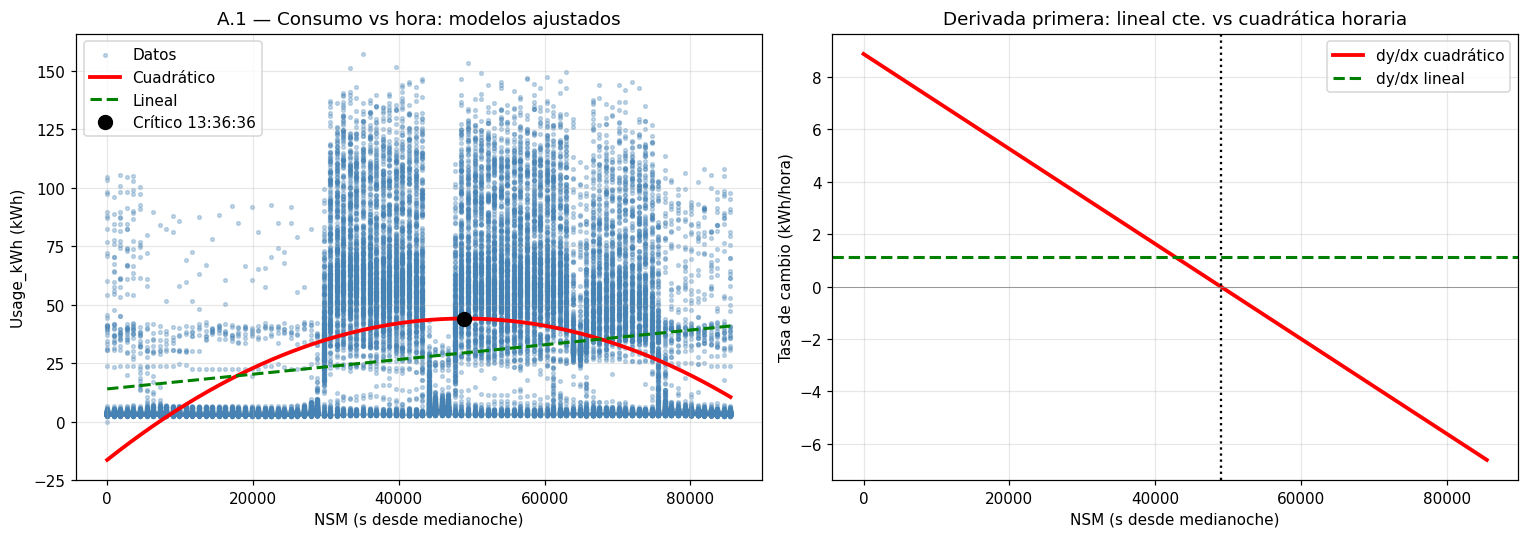

Figura guardada: figures/A1_modelos_comparacion.png


In [13]:
# Gráfico A.1: datos + modelos (izq.) y derivadas (der.)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Aca cambian el 35040 por la cantidad de muestreo que quieran, yo lo dejaria así, para mostrar todos
idx = np.random.choice(n, 35040, replace=False)
grid = np.linspace(0, 85500, 500)

ax = axes[0]
ax.scatter(x_nsm[idx], y_usage[idx], s=6, alpha=0.3, color='steelblue', label='Datos')
## Datos se puede cambiar por Datos (muestra de X) lo cambie para mostrar todos
ax.plot(grid, b0q + b1q*grid + b2q*grid**2, 'r-', lw=2.5, label='Cuadrático')
ax.plot(grid, b0l + b1l*grid, 'g--', lw=2, label='Lineal')
yc_plot = b0q + b1q*xc + b2q*xc**2
ax.plot(xc, yc_plot, 'ko', ms=9, label=f'Crítico {hh:02d}:{mm:02d}:{ss:02d}')
ax.set_xlabel('NSM (s desde medianoche)'); ax.set_ylabel('Usage_kWh (kWh)')
ax.set_title('A.1 — Consumo vs hora: modelos ajustados'); ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(grid, (b1q + 2*b2q*grid)*3600, 'r-', lw=2.5, label='dy/dx cuadrático')
ax.axhline(b1l*3600, color='g', ls='--', lw=2, label='dy/dx lineal')
ax.axvline(xc, color='k', ls=':', lw=1.5)
ax.axhline(0, color='gray', lw=0.5)
ax.set_xlabel('NSM (s desde medianoche)'); ax.set_ylabel('Tasa de cambio (kWh/hora)')
ax.set_title('Derivada primera: lineal cte. vs cuadrática horaria'); ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('figures/A1_modelos_comparacion.png', dpi=300, bbox_inches='tight')
plt.show()
print('Figura guardada: figures/A1_modelos_comparacion.png')

---
## A.2 — Derivadas parciales y ecuaciones normales

Para $f(b_0,b_1)=\sum_i[y_i-(b_0+b_1x_i)]^2$ con $x=$ `Lagging_Current_Reactive.Power_kVarh`:

$$\frac{\partial f}{\partial b_0}=-2\sum_i (y_i-b_0-b_1x_i),\qquad
\frac{\partial f}{\partial b_1}=-2\sum_i x_i\,(y_i-b_0-b_1x_i)$$

Igualando a cero se obtiene el sistema de ecuaciones normales y, resolviéndolo,
$\hat{\beta}_1=S_{xy}/S_{xx}$ y $\hat{\beta}_0=\bar{y}-\hat{\beta}_1\bar{x}$
(el desarrollo algebraico completo paso a paso está en `informe/resolucion_completa.md`, A.2).
A continuación se calculan con NumPy básico y se contrastan contra `statsmodels` y `scipy`.

In [ ]:
x_lag = df['Lagging_Current_Reactive.Power_kVarh'].values.astype(float)
xbar_lag, ybar = x_lag.mean(), y_usage.mean()
Sxx = ((x_lag - xbar_lag)**2).sum()
Sxy = ((x_lag - xbar_lag) * (y_usage - ybar)).sum()

beta1_a2 = Sxy / Sxx
beta0_a2 = ybar - beta1_a2 * xbar_lag

# Contraste con dos herramientas independientes
fit_sm = sm.OLS(y_usage, sm.add_constant(x_lag)).fit()
sl, ic, r_sci, p_sci, se_sci = stats.linregress(x_lag, y_usage)

print(f'x̄ = {xbar_lag:.6f} kVarh   ȳ = {ybar:.6f} kWh')
print(f'S_xx = {Sxx:.3f}   S_xy = {Sxy:.3f}')
tabla_a2 = pd.DataFrame({
    'Método': ['Fórmulas analíticas', 'statsmodels OLS', 'scipy.linregress'],
    'β̂₀': [beta0_a2, fit_sm.params[0], ic],
    'β̂₁': [beta1_a2, fit_sm.params[1], sl]})
tabla_a2['|β̂₀−β̂₀_sm|'] = (tabla_a2['β̂₀'] - fit_sm.params[0]).abs().apply('{:.1e}'.format)
tabla_a2['|β̂₁−β̂₁_sm|'] = (tabla_a2['β̂₁'] - fit_sm.params[1]).abs().apply('{:.1e}'.format)
tabla_a2.round(8)

assert np.abs(beta0_a2 - fit_sm.params[0]) < 1e-10 and np.abs(beta1_a2 - fit_sm.params[1]) < 1e-10
print(f'\nRECTA INFORMADA:  ŷ = {beta0_a2:.6f} + {beta1_a2:.6f}·x   (coincidencia < 1e-10 en las tres vías)')

---
## A.3 — Descenso del gradiente de la regresión múltiple (modelo B.5)

**Justificación (2 líneas):** $\nabla f(b)$ apunta hacia el máximo crecimiento de $f$; avanzar en $-\nabla f(b)$
sigue la dirección de máximo *decrecimiento* local del error cuadrático.

**Aspecto numérico:** `NSM` ~ $8,55\times10^4$ hace $\sum x_i^2\sim10^{14}$ (Hessiana mal condicionada).
Por ello se **estandarizan** las predictoras (z-score) y se minimiza el MSE
$f(\tilde{\beta})=\frac{1}{n}\lVert y-\tilde{X}\tilde{\beta}\rVert^2$, re-transformando al final:
$\hat{\beta}_j=\tilde{\beta}_j/s_j$, $\ \hat{\beta}_0=\tilde{\beta}_0-\sum_j\tilde{\beta}_j\bar{x}_j/s_j$.

In [ ]:
import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)

X_cols = ['Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh',
          'Lagging_Current_Power_Factor', 'NSM']
X_raw = df[X_cols].values
Xm, Xs = X_raw.mean(axis=0), X_raw.std(axis=0)
Xz = np.column_stack([np.ones(n), (X_raw - Xm) / Xs])        # diseñada escalada
Xo = np.column_stack([np.ones(n), X_raw])                    # diseñada original

# Solución exacta MCO en ambos espacios
bt_ols = np.linalg.solve(Xz.T @ Xz, Xz.T @ y_usage)          # espacio escalado
b_ols = np.linalg.solve(Xo.T @ Xo, Xo.T @ y_usage)           # espacio original
assert np.abs(b_ols - sm.OLS(y_usage, sm.add_constant(X_raw)).fit().params).max() < 1e-9

def to_orig(beta_tilde):
    out = np.zeros(Xz.shape[1])
    out[1:] = beta_tilde[1:] / Xs
    out[0] = beta_tilde[0] - (beta_tilde[1:] * Xm / Xs).sum()
    return out

def f_cost(Xb, yb, b):   resid = yb - Xb @ b;  return resid @ resid / len(yb)


In [ ]:
def gradiente(Xb, yb, b):
    return -2 / len(yb) * Xb.T @ (yb - Xb @ b)

def descenso_gradiente(Xb, yb, alpha, b0=None, K_max=50000, tol=1e-8):
    b = np.zeros(Xb.shape[1]) if b0 is None else b0.copy()
    h = []
    for k in range(K_max):
        h.append(f_cost(Xb, yb, b))
        b_new = b - alpha * gradiente(Xb, yb, b)
        if np.linalg.norm(b_new - b) / (np.linalg.norm(b) + 1e-12) < tol:
            return b_new, h, k + 1, True        # criterio: ||Δβ||/||β|| < 1e-8
        b = b_new
    return b, h, K_max, False

# Cota de estabilidad con los autovalores de la Hessiana escalada (2/n)·X'X
Hess = 2 / n * Xz.T @ Xz
eig = np.linalg.eigvals(Hess).real
lam_max, lam_min = eig.max(), eig.min()
a_max = 2 / lam_max
print(f'λ_max = {lam_max:.4f}   λ_min = {lam_min:.4f}   κ = {lam_max/lam_min:.2f}')
print(f'Cota: α < 2/λ_max = {a_max:.6f}  →  α_inestable = 1.5·({a_max:.4f}) DIVERGE')

alphas = {'α pequeña (0.01·2/λmax)': 0.01 * a_max,
          'α adecuada (0.5·2/λmax)': 0.50 * a_max,
          'α divergente (1.5·2/λmax)': 1.50 * a_max}

resultados_gd = {}
for nombre, al in alphas.items():
    b_f, h, k_it, conv = descenso_gradiente(Xz, y_usage, al)
    resultados_gd[nombre] = {'alpha': al, 'b': b_f, 'hist': h, 'it': k_it, 'conv': conv}
    diff = np.linalg.norm(to_orig(b_f) - b_ols) if conv else np.nan
    print(f'{nombre:26s} → iter={k_it:6d}  convergió={conv}  costo={h[-1]:.4f}  ‖β_GD−β_OLS‖={diff:.2e}' if conv
          else f'{nombre:26s} → iter={k_it:6d}  convergió={conv}  DIVERGE (f → ∞)')

In [ ]:
# Gráfico A.3: tres trayectorias de f en el mismo par de ejes
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
f_ols = f_cost(Xz, y_usage, bt_ols)

ax = axes[0]                                   # escala lineal: los dos convergentes
for nombre in list(alphas)[:2]:
    ax.plot(resultados_gd[nombre]['hist'], lw=2, label=nombre)
ax.axhline(f_ols, color='k', ls='--', lw=1, label='MCO exacto')
ax.set_xlabel('Iteración k'); ax.set_ylabel('Costo MSE'); ax.set_title('A.3 — Convergencia (escala lineal)')
ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]                                   # escala log: incluye la divergencia
for nombre in alphas:
    h_arr = np.clip(np.array(resultados_gd[nombre]['hist'], dtype=float), 1e-16, None)
    ax.semilogy(h_arr, lw=2, label=nombre)
ax.axhline(f_ols, color='k', ls='--', lw=1)
ax.set_xlabel('Iteración k'); ax.set_ylabel('Costo MSE (log)'); ax.set_title('A.3 — Los tres regímenes')
ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('figures/A3_gradient_descent.png', dpi=300, bbox_inches='tight')
plt.show()

# Comparación final GD(0.5·αmax) vs MCO exacto
b_adec = to_orig(resultados_gd['α adecuada (0.5·2/λmax)']['b'])
nombres = ['β₀', 'β₁ Lagging kVarh', 'β₂ Leading kVarh', 'β₃ Lagging PF', 'β₄ NSM']
tabla_gd = pd.DataFrame({'Parámetro': nombres, 'MCO exacto': b_ols,
                         'GD (α adecuada)': b_adec,
                         '|diff|': np.abs(b_ols - b_adec)})
tabla_gd.round(8)

---
## B.1 — Varianza: $STC = SCR + SCE$, $\hat{\sigma}^2$ y $R^2$

Modelo simple Usage_kWh ~ `Lagging_Current_Reactive.Power_kVarh` (recta de A.2).
$\hat{\sigma}^2=SCE/(n-2)$ es la estimación insesgada de la varianza del error y
$R^2=1-SCE/STC=SCR/STC$ la proporción de variabilidad explicada.

In [ ]:
yhat_a2 = fit_sm.fittedvalues
STC = ((y_usage - ybar)**2).sum()
SCR = ((yhat_a2 - ybar)**2).sum()
SCE = ((y_usage - yhat_a2)**2).sum()
sigma2_b1 = SCE / (n - 2)
R2_b1 = 1 - SCE / STC

tabla_b1 = pd.DataFrame({'Componente': ['Regresión (SCR)', 'Error (SCE)', f'Total (STC)'],
                         'Suma de cuadrados': [SCR, SCE, STC],
                         'gl': [1, n - 2, n - 1],
                         'Cuadrado medio': [SCR / 1, SCE / (n - 2), STC / (n - 1)]})
print(tabla_b1.to_string(index=False, float_format=lambda v: f'{v:,.4f}'))
print(f'\n|STC − (SCR+SCE)| = {abs(STC - SCR - SCE):.2e}  (< 1e-6 → identidad verificada)')
print(f'σ̂² = SCE/(n−2) = {sigma2_b1:.6f} kWh²   →   R̂ = √σ̂² = {np.sqrt(sigma2_b1):.4f} kWh')
print(f'R² = 1 − SCE/STC = {R2_b1:.6f}   (forma equivalente SCR/STC = {SCR/STC:.6f})')

> **Qué NO significa $R^2=0,803$:**
> 1. **No hay causalidad demostrada** — solo asociación lineal (ambas variables se mueven juntas con la carga productiva).
> 2. **No garantiza que la forma funcional sea correcta** — podría existir curvatura no capturada por la recta.
> 3. **No mide la magnitud de la pendiente** ni protege contra sesgo por variables omitidas (`Load_Type`, horarios, día de la semana).
> 4. **No asegura predicciones individuales precisas** — el error típico por intervalo es $\sqrt{\hat{\sigma}^2}\approx14,84$ kWh (ver IP en B.4).

---
## B.2 — Regresión lineal simple con las cuatro predictoras

Se ajusta Usage_kWh contra cada una de las cuatro variables y se completa el cuadro con
IC de coeficientes, ICM e IP (95%, $\alpha=0,05$) evaluados en $x^{*}=20$ (valor fijado en B.4,
interpretado en las unidades de cada predictora). $t(0,025;\,35\,038)=1,960032$.

In [ ]:
t_crit = stats.t.ppf(0.975, n - 2)
x_star = 20
X_cols_orden = ['Lagging_Current_Reactive.Power_kVarh',
                'Leading_Current_Reactive_Power_kVarh',
                'Lagging_Current_Power_Factor', 'NSM']

filas = []
for col in X_cols_orden:
    xi = df[col].values.astype(float)
    mod = sm.OLS(y_usage, sm.add_constant(xi)).fit()
    b0i, b1i = mod.params
    s2i, R2i = mod.scale, mod.rsquared
    xb, Sx = xi.mean(), ((xi - xi.mean())**2).sum()
    se1 = np.sqrt(s2i / Sx)
    se0 = np.sqrt(s2i * (1/n + xb**2 / Sx))
    ys = b0i + b1i * x_star
    se_cm = np.sqrt(s2i * (1/n + (x_star - xb)**2 / Sx))
    se_pr = np.sqrt(s2i * (1 + 1/n + (x_star - xb)**2 / Sx))
    filas.append({'Variable': col, 'β̂₀': b0i, 'β̂₁': b1i, 'σ̂²': s2i, 'R²': R2i,
                  'IC(β₀) 95%': f'[{b0i - t_crit*se0:.4f}; {b0i + t_crit*se0:.4f}]',
                  'IC(β₁) 95%': f'[{b1i - t_crit*se1:.4f}; {b1i + t_crit*se1:.4f}]',
                  'ICM(Y|x*=20) 95%': f'[{ys - t_crit*se_cm:.4f}; {ys + t_crit*se_cm:.4f}]',
                  'IP(Y|x*=20) 95%': f'[{ys - t_crit*se_pr:.4f}; {ys + t_crit*se_pr:.4f}]',
                  '_b0': b0i, '_b1': b1i, '_s2': s2i, '_R2': R2i, '_x': xi,
                  '_xb': xb, '_Sx': Sx})

resumen_b2 = pd.DataFrame(filas)
fmt_b1 = lambda v: f'{v:+.4e}' if abs(v) < 1e-3 else f'{v:+.4f}'
tabla_b2 = resumen_b2.copy()
tabla_b2['Modelo ŷ=β̂₀+β̂₁x'] = tabla_b2['β̂₀'].round(4).astype(str) + ' ' + tabla_b2['β̂₁'].map(fmt_b1) + '·x'
mostrar = tabla_b2[['Variable', 'Modelo ŷ=β̂₀+β̂₁x', 'σ̂²', 'R²',
                    'IC(β₀) 95%', 'IC(β₁) 95%', 'ICM(Y|x*=20) 95%', 'IP(Y|x*=20) 95%']]
mostrar.round(8)


In [ ]:
mejor = resumen_b2.loc[resumen_b2['_R2'].idxmax()]
print(f"MEJOR PREDICTORA: {mejor['Variable']}   R² = {mejor['_R2']:.6f}   σ̂² = {mejor['_s2']:.4f}")
print('Justificación: máximo R² (5× el segundo), mínima varianza residual y coherencia física')
print('(hornos y motores de inducción consumen potencia activa y reactiva inductiva acopladas).')

# Diagrama de dispersión con la recta ajustada superpuesta
xi_best = mejor['_x']
idx_b2 = np.random.choice(n, 5000, replace=False)
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(xi_best[idx_b2], y_usage[idx_b2],
           s=6, alpha=0.3, color='steelblue', label='Datos (muestra 5000)')
gridb = np.linspace(xi_best.min(), xi_best.max(), 300)
ax.plot(gridb, mejor['_b0'] + mejor['_b1'] * gridb, 'r-', lw=2.5,
        label=f"ŷ = {mejor['_b0']:.4f} + {mejor['_b1']:.4f}·x")
ax.set_xlabel(mejor['Variable']); ax.set_ylabel('Usage_kWh (kWh)')
ax.set_title(f"B.2 — Regresión simple con la mejor predictora (R² = {mejor['_R2']:.4f})")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('figures/B2_mejor_modelo.png', dpi=300, bbox_inches='tight')
plt.show()

---
## B.3 — Test de hipótesis sobre la pendiente del mejor modelo

$$H_0:\beta_1=0\quad vs.\quad H_1:\beta_1\neq0,\qquad
T=\frac{\hat{\beta}_1}{\sqrt{\hat{\sigma}^2/S_{xx}}}\ \sim\ t_{(n-2)},\qquad
\text{rechazar }H_0\text{ si }|T|>t(0,025;\,n-2).$$

In [ ]:
T_b3 = mejor['_b1'] / np.sqrt(mejor['_s2'] / mejor['_Sx'])
p_b3 = 2 * (1 - stats.t.cdf(abs(T_b3), n - 2))
print(f'β̂₁ = {mejor["_b1"]:.6f}   σ̂² = {mejor["_s2"]:.6f}   S_xx = {mejor["_Sx"]:.3f}')
print(f'T  = {T_b3:.6f}')
print(f'crítico t(0.025, {n-2}) = {t_crit:.6f}')
print(f'p-valor = {p_b3:.2e}')
print(f'¿|T| > t_crit?  {abs(T_b3) > t_crit}   →   SE RECHAZA H₀')
print()
print('CONCLUSIÓN (lenguaje industrial): existe evidencia abrumadora de que la potencia')
print('reactiva inductiva está linealmente asociada al consumo eléctrico de la planta:')
print(f'cada kVarh adicional de reactiva inductiva se asocia en promedio a +{mejor["_b1"]:.4f} kWh')
print('en el intervalo de 15 minutos; el medidor de reactiva funciona como termómetro de la')
print('carga de hornos y motores, útil para anticipar la factura.')

---
## B.4 — Intervalos para la respuesta media y de predicción ($x^{*}=20$ kVarh)

**ICM** acota el *consumo promedio* de todas las cuartetas con 20 kVarh (parámetro $\beta_0+\beta_1x^{*}$);
**IP** acota el consumo de *una única cuarteta futura*, incorporando además la variabilidad
irreducible $\hat{\sigma}^2$ — por eso es mucho más ancho.

In [ ]:
ys_b4 = mejor['_b0'] + mejor['_b1'] * x_star
se_icm = np.sqrt(mejor['_s2'] * (1/n + (x_star - mejor['_xb'])**2 / mejor['_Sx']))
se_ip  = np.sqrt(mejor['_s2'] * (1 + 1/n + (x_star - mejor['_xb'])**2 / mejor['_Sx']))
m_icm, m_ip = t_crit * se_icm, t_crit * se_ip

print(f'ŷ* = β̂₀ + β̂₁·x* = {mejor["_b0"]:.6f} + {mejor["_b1"]:.6f}×20 = {ys_b4:.6f} kWh')
print(f'n = {n}   x̄ = {mejor["_xb"]:.6f}   S_xx = {mejor["_Sx"]:.3f}   σ̂² = {mejor["_s2"]:.6f}   t = {t_crit:.6f}')
print()
print(f'ICM:  y* ± t·√[σ̂²(1/n+(x*−x̄)²/S_xx)] = {ys_b4:.4f} ± {m_icm:.4f}')
print(f'      ICM(Y|x*=20) = [{ys_b4-m_icm:.4f}; {ys_b4+m_icm:.4f}] kWh')
print(f'IP :  y* ± t·√[σ̂²(1+1/n+(x*−x̄)²/S_xx)] = {ys_b4:.4f} ± {m_ip:.4f}')
print(f'      IP(Y|x*=20)  = [{ys_b4-m_ip:.4f}; {ys_b4+m_ip:.4f}] kWh')
print()
print(f'El IP es amplio_IP/amplio_ICM = {m_ip/m_icm:.0f}× ancho: la recta promedia muy bien,')
print('pero una cuarteta individual puede desviarse ~15 kWh del valor esperado.')

---
## B.5 — Regresión múltiple por mínimos cuadrados matriciales

$\hat{\beta}=(X^TX)^{-1}X^TY$ con $X\in\mathbb{R}^{35040\times5}$ (unos + 4 predictoras).
Se reportan $X^TX$, su inversa, $\hat{\beta}$ y el $R^2$ ajustado **por ambas fórmulas**
(enunciado PDF y estándar bibliográfica: con $n=35\,040$, $k=4$ prácticamente coinciden).

In [ ]:
XTX = Xo.T @ Xo
XTX_inv = np.linalg.inv(XTX)
XTy = Xo.T @ y_usage
beta_b5 = XTX_inv @ XTy
assert np.abs(beta_b5 - b_ols).max() < 1e-9          # coincide con A.3

names = ['1', 'Lag kVarh', 'Lead kVarh', 'Lag PF', 'NSM']
nombres_param = ['β₀', 'β₁ (Lagging kVarh)', 'β₂ (Leading kVarh)', 'β₃ (Lagging PF)', 'β₄ (NSM)']
fmt_e = lambda v: f'{v:.4e}'

print('MATRIZ X^T X (5×5):')
print(pd.DataFrame([[fmt_e(v) for v in f_ila] for f_ila in XTX], index=names, columns=names))
print('\nINVERSA (X^T X)^-1:')
print(pd.DataFrame([[fmt_e(v) for v in fila] for fila in XTX_inv], index=names, columns=names))
print('\nX^T y:', np.array2string(XTy, precision=4))

yhat_b5 = Xo @ beta_b5
STC_b5 = STC
SCE_b5 = ((y_usage - yhat_b5)**2).sum()
SCR_b5 = STC_b5 - SCE_b5
R2_b5 = 1 - SCE_b5 / STC_b5
R2_adj_enu = 1 - (1 - R2_b5) * (n - 4) / (n - 4 - 1)        # fórmula del enunciado
R2_adj_std = 1 - (1 - R2_b5) * (n - 1) / (n - 4 - 1)       # fórmula estándar
R2_adj_simple = 1 - (1 - R2_b1) * (n - 1) / (n - 2)

print(f'\nValidación statsmodels: máx |diff| = {np.abs(beta_b5 - sm.OLS(y_usage, sm.add_constant(X_raw)).fit().params).max():.1e}')
print(f'STC = {STC_b5:,.1f}   SCR = {SCR_b5:,.1f}   SCE = {SCE_b5:,.1f}')
print(f'R² = {R2_b5:.6f}')
print(f'R² ajustado (enunciado, (n−k)/(n−k−1)) = {R2_adj_enu:.6f}')
print(f'R² ajustado (estándar, (n−1)/(n−k−1))  = {R2_adj_std:.6f}')
print(f'→ coinciden hasta el 4º decimal (diferencia {abs(R2_adj_enu-R2_adj_std):.1e})')
print(f'\nR² simple (B.2) = {R2_b1:.6f} → múltiple = {R2_b5:.6f}   (+= {(R2_b5-R2_b1)*100:.2f} pp)')
print(f'R² ajustado simple = {R2_adj_simple:.6f}  |  múltiple = {R2_adj_std:.6f}')

eq = f'ŷ = {beta_b5[0]:.4f}'
for j in range(1, 5):
    eq += f' {"+" if beta_b5[j] >= 0 else "-"} {abs(beta_b5[j]):.4e}·{X_cols[j-1]}'
print(f'\nMODELO FINAL: {eq}')
print(f'              R² = 0,8992   R² ajustado = 0,8992 (ambas fórmulas)')

---
## Anexo I — Bitácora de uso de IA (síntesis)

| # | Herramienta | Pedido | Resultado | ¿Aceptado? |
|---|---|---|---|---|
| 1 | opencode (GLM) | Código A.1 (derivadas, punto crítico) | `src/parte_a_analisis.py` | Sí, con fixes menores |
| 2 | opencode (GLM) | Informe A.1 paso a paso | `informe/resolucion_completa.md` | Sí |
| 3 | opencode (GLM) | Código A.2 + A.3 (DG con 3 α) | `src/parte_a2_a3.py` | Sí, con fixes numéricos |
| 4 | opencode (GLM) | Informe A.2 + A.3 | Secciones de la Parte A | Sí |
| 5 | opencode (GLM) | Código B.1–B.5 según TRABAJO.md | `src/parte_b_estadistica.py` | Sí, con nota sobre extrapolación |
| 6 | opencode (GLM) | Redacción B.1–B.5 + este notebook | Secciones 17–22 del informe | Sí |

**Reproducibilidad:** `np.random.seed(42)`; todos los números provienen de este notebook y de los scripts en `src/`.
Figuras generadas (300 DPI): `figures/A1_modelos_comparacion.png`, `figures/A3_gradient_descent.png`, `figures/B2_mejor_modelo.png`.